# Chuẩn bị
Ta tải các thư viện hỗ trợ vào và download ảnh ví dụ

In [ ]:
import cv2 # Tải thư viện OpenCV
import numpy as np # Tải thư viện Numpy
from google.colab.patches import cv2_imshow # Tải hàm cv2_imshow

import math # thư viện các hàm toán học
import matplotlib.pyplot as plt # thư viện hỗ trợ vẽ đồ thị

!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg
!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/basketball1.png
!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/basketball2.png

# Tính histogram

Khi dùng historam với vai trò như đặc trưng phục vụ việc phân tích nhận dạng, ta thường tính histogram với việc chia khoảng các mức xám và đếm các giá trị điểm ảnh trong từng khoảng mức xám.

Lúc này, ta sẽ xét trên ảnh xám mặc định với giá trị điểm ảnh trong [0, 255].

In [ ]:
# I: ảnh xám đầu vào
# n: số khoảng, thường là 1 giá trị hàm mũ của 2 như 4,8,16..
def tinh_histogram2(I, n):
    t = 1.0*256/n
    ranges = [ [math.ceil(t*i), math.ceil(t*(i+1))-1] for i in range(n)]

    h = np.zeros(n, np.int32)
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            for k in range(n):
                if I[i, j]>=ranges[k][0] and I[i, j]<=ranges[k][1]:
                    h[k] = h[k]+1
                    break
    return h

In [ ]:
I = np.array([
    [214,101,47,96,82],
    [96,53,164,188,184],
    [170,15,98,86,98],
    [114,220,63,223,148],
    [229,22,200,214,106]
], dtype=np.uint8)
print("anh dau vao:")
print(I)

# tính với dữ liệu chia 4 khoảng
h1 = tinh_histogram2(I, 4)
print("histogram (4 khoang):", h1)

anh dau vao:
[[214 101  47  96  82]
 [ 96  53 164 188 184]
 [170  15  98  86  98]
 [114 220  63 223 148]
 [229  22 200 214 106]]
histogram (4 khoang): [5 9 5 6]


Ta chỉnh sửa để in các khoảng tính được ra

In [ ]:
# I: ảnh xám đầu vào
# n: số khoảng, thường là 1 giá trị hàm mũ của 2 như 4,8,16..
def tinh_histogram2(I, n):
    t = 1.0*256/n
    ranges = [ [math.ceil(t*i), math.ceil(t*(i+1))-1] for i in range(n)]

    h = np.zeros(n, np.int32)
    for i in range(I.shape[0]):
        for j in range(I.shape[1]):
            for k in range(n):
                if I[i, j]>=ranges[k][0] and I[i, j]<=ranges[k][1]:
                    h[k] = h[k]+1
                    break
    return h, ranges

Tính lại và in ra các khoảng

In [ ]:
h1, rs1 = tinh_histogram2(I, 4)
print("4 khoang:", *rs1)
print("histogram:", h1)

4 khoang: [0, 63] [64, 127] [128, 191] [192, 255]
histogram: [5 9 5 6]


Vẽ histogram

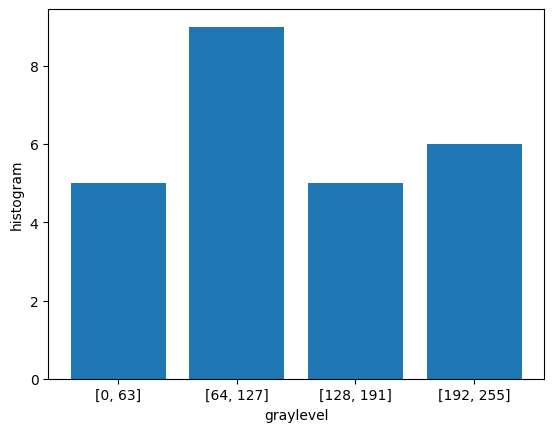

In [ ]:
plt.bar([str(r) for r in rs1], h1)
plt.xlabel('graylevel')
plt.ylabel('histogram')
plt.show()

Thử với một số kết quả khác

In [ ]:
h2, rs2 = tinh_histogram2(I, 8)
print("8 khoang:", *rs2)
print("histogram:", h2)

8 khoang: [0, 31] [32, 63] [64, 95] [96, 127] [128, 159] [160, 191] [192, 223] [224, 255]
histogram: [2 3 2 7 1 4 5 1]


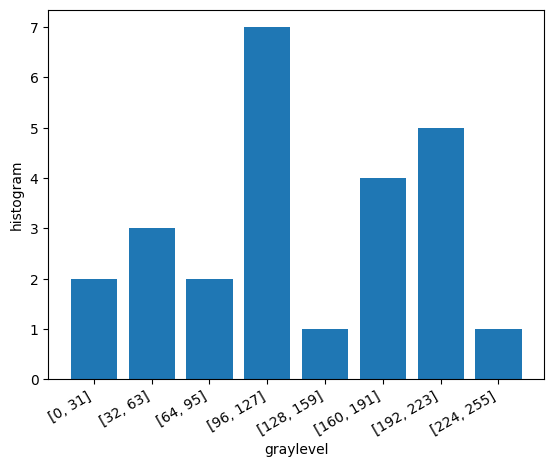

In [ ]:
plt.bar([str(r) for r in rs2], h2)
plt.xlabel('graylevel')
plt.ylabel('histogram')
plt.xticks(rotation=30, ha='right')
plt.show()

# Đối sánh histogram

Ta xét một số phương pháp như sau:

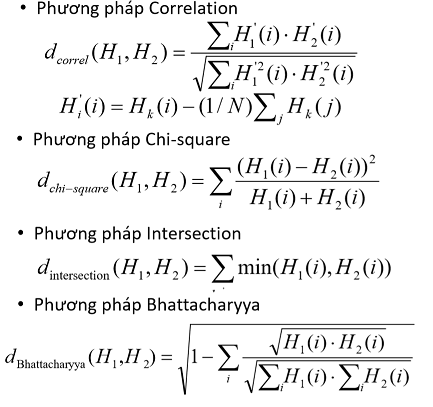

*Lưu ý: Trong làm việc với ảnh thực tế, người ta thường sử dụng histogram chuẩn hóa, chẳng hạn chia tất cả các giá trị của histogram cho số lượng điểm ảnh.*

Ta xây dựng ví dụ hai trường hợp là Chi-square và Intersection:

In [ ]:
def chi_square(h1, h2):
    v= 0.0
    for i in range(h1.shape[0]):
        v = v + 1.0*(h1[i]-h2[i])*(h1[i]-h2[i])/(h1[i]+h2[i])
    return v
def intersection(h1, h2):
    v= 0.0
    for i in range(h1.shape[0]):
        v = v + min(h1[i], h2[i])
    return v

Ta chạy thử với ảnh tự tạo:

In [ ]:
I_1 = np.array([
    [224, 5, 181, 185, 38],
    [103, 60, 101, 160, 186],
    [57, 199, 175, 51, 36],
    [71, 166, 32, 30, 86]
], dtype=np.uint8)

I_2 = np.array([
    [199, 20, 129, 175, 111],
    [68, 188, 221, 141, 49],
    [94, 254, 88, 135, 112],
    [198, 66, 69, 8, 199]
], dtype=np.uint8)

print("Tinh histogram voi du lieu chia 4 khoang.")
H_1, rs = tinh_histogram2(I_1, 4)
H_2, _ = tinh_histogram2(I_2, 4)
print("Cac khoang:", rs)
print("H1:", H_1)
print("H2:", H_2)
print("Chi square:", chi_square(H_1, H_2))
print("Intersection:", intersection(H_1, H_2))

Tinh histogram voi du lieu chia 4 khoang.
Cac khoang: [[0, 63], [64, 127], [128, 191], [192, 255]]
H1: [8 4 6 2]
H2: [3 7 5 5]
Chi square: 4.467532467532468
Intersection: 14.0


# Histogram backprojection

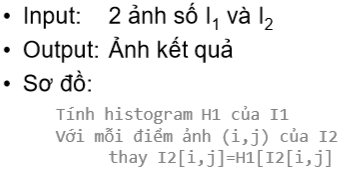

Lưu ý:
*   Về ý tưởng cơ bản, việc tính toán là với H1 và I2: thực hiện "chiếu ngược" H1 lên I2
*   Sơ đồ trên minh họa cơ bản ý tưởng thuật toán và phục vụ tính bài tập. Để tham khảo thêm mô tả khác, xem https://docs.opencv.org/4.x/dc/df6/tutorial_py_histogram_backprojection.html

In [ ]:
# Theo sơ đồ thuật toán:
# H1: histogram
# I2: ảnh xám I2
# ranges: các khoảng của H1
def histogram_backprojection(H1, I2, ranges):
    I_bp = np.zeros(I2.shape, np.float32)
    for i in range(I2.shape[0]):
        for j in range(I2.shape[1]):
            for k in range(len(ranges)):
                if I2[i, j]>=ranges[k][0] and I2[i, j]<=ranges[k][1]:
                    I_bp[i, j] = H1[k]
                    break
    return I_bp

# Theo sơ đồ thuật toán:
# I1: ảnh xám I1
# I2: ảnh xám I2
# n: số khoảng tính histogram
def histogram_backprojection2(I1, I2, n):
    H1, ranges = tinh_histogram2(I1, n)
    return histogram_backprojection(H1, I2, ranges)


Ta áp dụng với ví dụ ở trên:


In [ ]:
I_b2 = histogram_backprojection(H_1, I_2, rs)
print("anh I2")
print(I_2)
print("\nhistogram H1:")
for i in range(len(rs)): print(rs[i], ":", H_1[i])
print("\nanh backproject cua H1 va I2")
print(I_b2)

anh I2
[[199  20 129 175 111]
 [ 68 188 221 141  49]
 [ 94 254  88 135 112]
 [198  66  69   8 199]]

histogram H1:
[0, 63] : 8
[64, 127] : 4
[128, 191] : 6
[192, 255] : 2

anh backproject cua H1 va I2
[[2. 8. 6. 6. 4.]
 [4. 6. 2. 6. 8.]
 [4. 2. 4. 6. 4.]
 [2. 4. 4. 8. 2.]]


# Thử nghiệm với ảnh thông thường đọc từ file

Ta đọc file dạng ảnh xám:

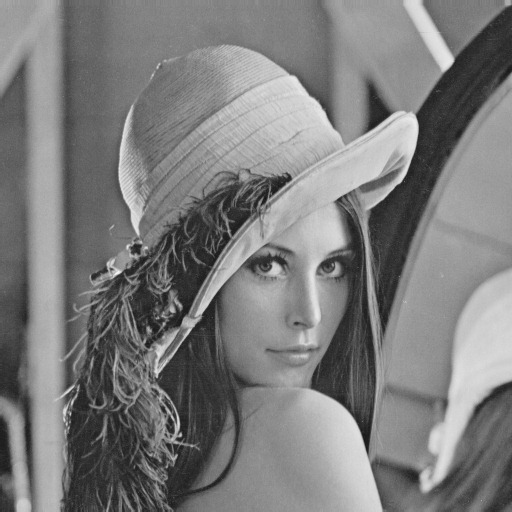

In [ ]:
I1 = cv2.imread("/content/lena.jpg", cv2.IMREAD_GRAYSCALE)
cv2_imshow(I1)

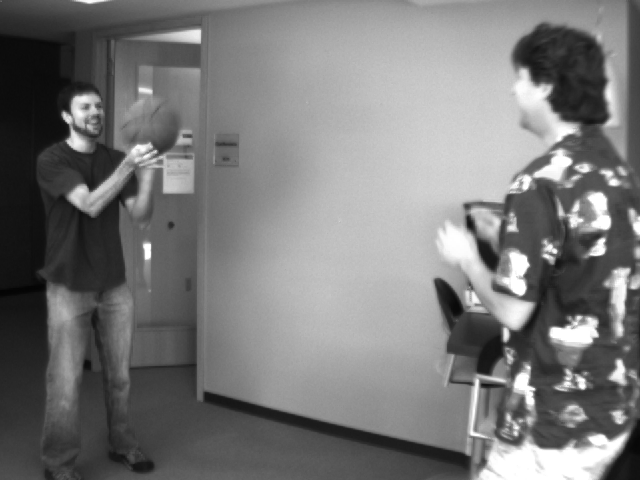

In [ ]:
I2 = cv2.imread("/content/basketball1.png", cv2.IMREAD_GRAYSCALE)
cv2_imshow(I2)

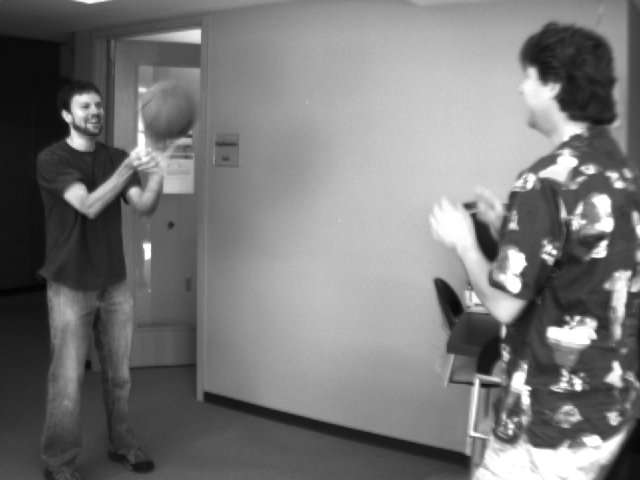

In [ ]:
I3 = cv2.imread("/content/basketball2.png", cv2.IMREAD_GRAYSCALE)
cv2_imshow(I3)

Ta tính các histogram với dữ liệu chia 16 khoảng

In [ ]:
h_1, rs = tinh_histogram2(I1, 16)
h_2, _ = tinh_histogram2(I2, 16)
h_3, _ = tinh_histogram2(I3, 16)

print("h_1", h_1)
print("h_2", h_2)
print("h_3", h_3)

h_1 [    0   468 16827 25093 13597 17459 27127 27067 35047 38910 22793 13180
 14390  9671   511     4]
h_2 [ 6095 16664 20438 24062 31140 26983 15989 19496 24210 25834 22435 29939
 26400  7017  2585  7913]
h_3 [ 6135 16675 21333 24403 31433 26688 15538 18479 24592 26398 23240 28517
 26127  6757  2810  8075]


Ta thực hiện chuẩn hóa:

In [ ]:
h_1 = h_1.astype(np.float32)/(I1.shape[0]*I1.shape[1])
h_2 = h_2.astype(np.float32)/(I2.shape[0]*I2.shape[1])
h_3 = h_3.astype(np.float32)/(I3.shape[0]*I3.shape[1])

print("h_1", h_1)
print("h_2", h_2)
print("h_3", h_3)

h_1 [0.00000000e+00 1.78527832e-03 6.41899109e-02 9.57221985e-02
 5.18684387e-02 6.66007996e-02 1.03481293e-01 1.03252411e-01
 1.33693695e-01 1.48429871e-01 8.69483948e-02 5.02777100e-02
 5.48934937e-02 3.68919373e-02 1.94931030e-03 1.52587891e-05]
h_2 [0.01984049 0.05424479 0.06652995 0.07832682 0.10136719 0.08783529
 0.05204753 0.06346354 0.07880859 0.08409505 0.0730306  0.09745768
 0.0859375  0.0228418  0.00841471 0.02575846]
h_3 [0.0199707  0.0542806  0.06944336 0.07943685 0.10232096 0.086875
 0.05057943 0.06015299 0.08005208 0.08593099 0.07565104 0.09282878
 0.08504883 0.02199544 0.00914714 0.02628581]


Ta vẽ các histogram

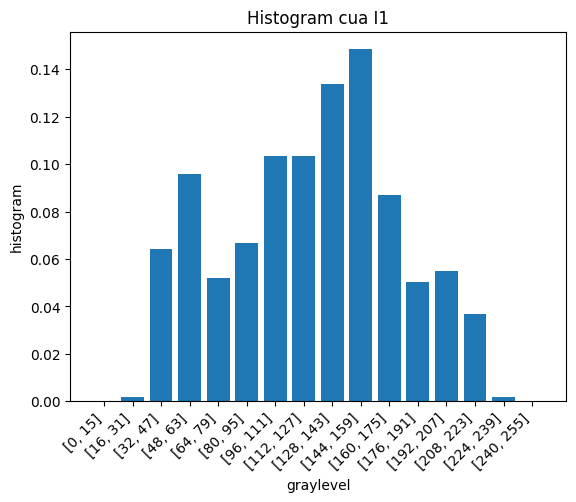

In [ ]:
plt.bar([str(r) for r in rs], h_1)
plt.title('Histogram cua I1')
plt.xlabel('graylevel')
plt.ylabel('histogram')
plt.xticks(rotation=45, ha='right')
plt.show()

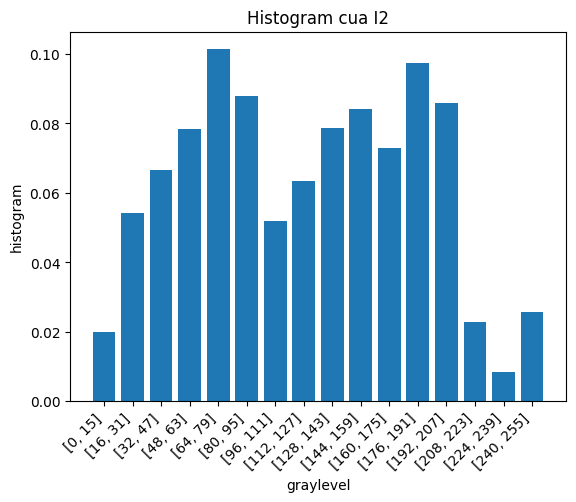

In [ ]:
plt.bar([str(r) for r in rs], h_2)
plt.title('Histogram cua I2')
plt.xlabel('graylevel')
plt.ylabel('histogram')
plt.xticks(rotation=45, ha='right')
plt.show()

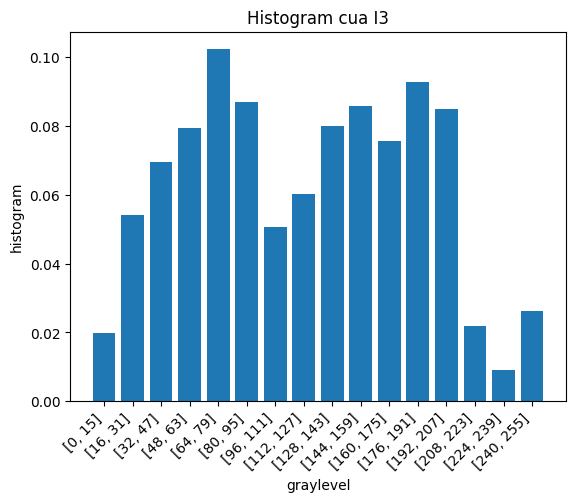

In [ ]:
plt.bar([str(r) for r in rs], h_3)
plt.title('Histogram cua I3')
plt.xlabel('graylevel')
plt.ylabel('histogram')
plt.xticks(rotation=45, ha='right')
plt.show()

Nhìn từ biểu đồ ta nhận thấy h_2 và h_3 có độ tương đồng cao hơn và khác với h_1, cũng như nhìn vào I2 và I3 so với I1.

Như vậy việc đối sánh được kỳ vọng cũng sẽ cần phản ảnh điều này.

Tức là:
*   chi_square(h_1, h_2) > chi_square(h_2, h_3)
*   intersection(h_1, h_2) < intersection(h_2, h_3)

In [ ]:
# xét với chi_square
print("chi_square(h_1, h_2): ", chi_square(h_1, h_2))
print("chi_square(h_2, h_3): ", chi_square(h_2, h_3))

chi_square(h_1, h_2):  0.2042995798481772
chi_square(h_2, h_3):  0.000434904817373194


In [ ]:
# xét với intersection
print("intersection(h_1, h_2): ", intersection(h_1, h_2))
print("intersection(h_2, h_3): ", intersection(h_2, h_3))

intersection(h_1, h_2):  0.7441941324869791
intersection(h_2, h_3):  0.9878971354166667


# Một số bài tập thực hành



**Câu 1:** Thực hành lập trình nốt 2 phương pháp đối sánh còn lại

**Câu 2:** Áp dụng với ảnh màu, thực hiện việc chia khoảng trên nhiều kênh.

Ví dụ như histogram sau:

| Red\Green | 0-63 | 64-127 | 128-191 | 192-255 |
| --- | --- | --- | --- | --- |
| 0-127 | 10 | 30 | 50 | 70 |
| 128-255 | 20 | 40 | 60 | 80 |

Như vậy trên ảnh sẽ có 30 điểm ảnh có giá trị kênh Red trong [0, 127] đồng thời giá trị kênh Green trong [64, 127]

**Câu 3:** Thực hành một ví dụ tra cứu ảnh đơn giản như sau:

Chuẩn bị:
*   1 thư mục ảnh (chúng ta sẽ tra cứu ảnh mới trong tập ảnh này).

Với đầu vào là ảnh quy vấn Q, các bước thực hiện:
*   Thực hiện đối sánh ảnh truy vấn Q với tất cả các ảnh trong tập ảnh đã chuẩn bị, như vậy với mỗi ảnh trong tập ta sẽ có một giá trị đối sánh.
*   Thực hiện tìm kiếm k ảnh tương đồng nhất là k ảnh có các giá trị đối sánh lớn nhất (hoặc bé nhất tùy theo phương pháp đối sánh). Có thể chọn k = 5, 10.
*   Hiển thị k ảnh tìm được và quan sát để kiểm chứng sự tương đồng.

**Câu 4:** Sử dụng việc tính histogram với ảnh màu (tham khảo câu 2), áp dụng histogram backprojection với ví dụ sau:
*   I2 là ảnh bàn tay (ví dụ như chụp bàn tay giơ trước webcam)
*   I1 là ảnh 1 vùng da tay (có thể chụp như trên và dùng MS Paint cắt ra 1 vùng)
*   Ảnh kết quả cuối được chuyển đổi để [MIN, MAX] giá trị điểm ảnh về [0, 255] và kiểu dữ liệu và np.uint8

Hiển thị ảnh kết quả và giải thích.

**Mở rộng:** Đọc ảnh từ webcam và liên tục tính histogram backprojection như trên đối với khung hình hiện tại.